# 12 · Probability for policies: Gaussians, MLE, and why MSE averages modes

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

def gaussian_nll(x, mu, sigma):
    return 0.5 * np.log(2 * np.pi * sigma**2) + (x - mu) ** 2 / (2 * sigma**2)

def demos_two_ways(n, rng):
    """Obstacle at x=0: half the demonstrators go left (-1), half go right (+1)."""
    obs = rng.uniform(-1, 1, (n, 1))
    side = rng.choice([-1.0, 1.0], n)
    act = side + 0.1 * rng.normal(size=n)
    return obs.astype(np.float32), act.astype(np.float32)[:, None]

def train(model, loss_fn, x, y, steps=2000, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    x, y = torch.tensor(x), torch.tensor(y)
    for _ in range(steps):
        loss = loss_fn(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    return model

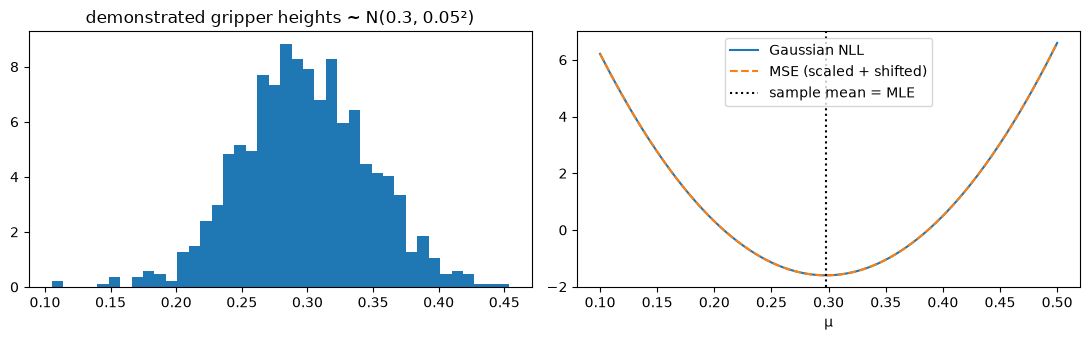

In [2]:
rng = np.random.default_rng(0)
samples = rng.normal(0.3, 0.05, 1000)
mus = np.linspace(0.1, 0.5, 400)
nll = [gaussian_nll(samples, m, 0.05).mean() for m in mus]
mse = [((samples - m) ** 2).mean() for m in mus]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(samples, 40, density=True); ax[0].set_title("demonstrated gripper heights ~ N(0.3, 0.05²)")
ax[1].plot(mus, nll, label="Gaussian NLL"); ax[1].plot(mus, np.array(mse) / (2 * 0.05**2) + nll[0] - mse[0] / (2 * 0.05**2), "--", label="MSE (scaled + shifted)")
ax[1].axvline(samples.mean(), c="k", ls=":", label="sample mean = MLE"); ax[1].legend(); ax[1].set_xlabel("μ")
plt.tight_layout(); plt.show()

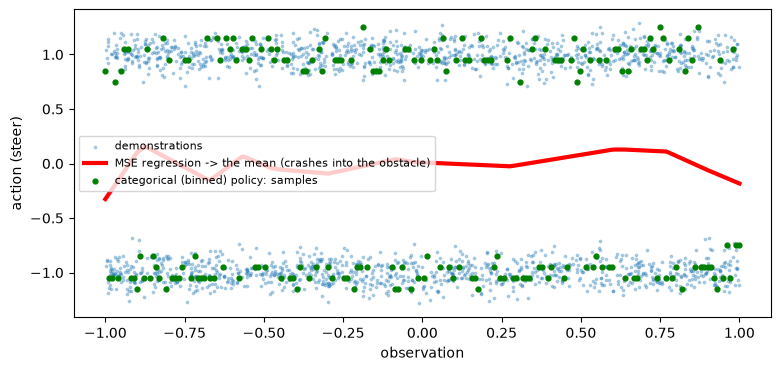

In [3]:
x, y = demos_two_ways(2000, rng)
mse_model = train(nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 1)), nn.MSELoss(), x, y)
bins = np.linspace(-1.5, 1.5, 31)
centers = (bins[:-1] + bins[1:]) / 2
labels = np.clip(np.digitize(y[:, 0], bins) - 1, 0, 29)
ce_model = train(nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 30)), nn.CrossEntropyLoss(), x, labels.astype(np.int64))
xs = torch.linspace(-1, 1, 200)[:, None]
with torch.no_grad():
    pred_mse = mse_model(xs).numpy()[:, 0]
    probs = torch.softmax(ce_model(xs), -1).numpy()
samples_ce = np.array([centers[rng.choice(30, p=p / p.sum())] for p in probs])
plt.figure(figsize=(9, 4))
plt.scatter(x[:, 0], y[:, 0], s=3, alpha=0.3, label="demonstrations")
plt.plot(xs[:, 0], pred_mse, "r", lw=3, label="MSE regression -> the mean (crashes into the obstacle)")
plt.scatter(xs[:, 0], samples_ce, s=12, c="g", label="categorical (binned) policy: samples")
plt.xlabel("observation"); plt.ylabel("action (steer)"); plt.legend(fontsize=8); plt.show()

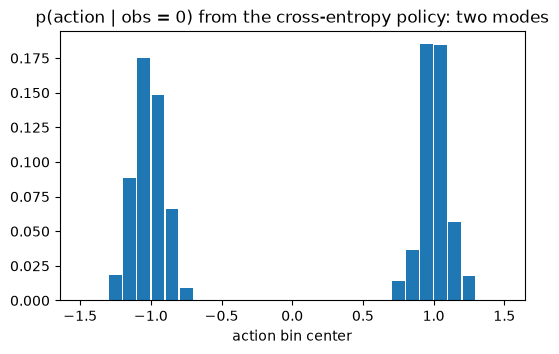

In [4]:
plt.figure(figsize=(6, 3.5))
plt.bar(centers, probs[100], width=0.09)
plt.title("p(action | obs = 0) from the cross-entropy policy: two modes"); plt.xlabel("action bin center"); plt.show()